# VERDE - ResNet-50: Training Strategy Ablation
### Smart Recycling and Waste Segregation Assistant - frozen vs fine-tuned and resampling vs class weights, three seeds each

**Question:** Do the training-strategy conclusions found on EfficientNet-B0 also hold for ResNet-50, and does the best configuration justify ResNet-50's size and CPU time?

**Answer:** The EfficientNet-B0 conclusions hold for ResNet-50: fine-tuning is essential (92.7% against 84%), and resampling vs class weights makes no measurable difference. ResNet-50 reaches 92.7% over three seeds, about 1.8 points below EfficientNet-B0, at 6 times the file size and about 2 times the CPU time.

<a id="section-1"></a>
## Section 1: Aim and Method

**Goal:** State what is being tested and why the result can be trusted.

**Why this model:** ResNet-50 had the best ResNet validation macro-F1 (0.928, against 0.923 for ResNet-18 and 0.917 for ResNet-34) and the best ResNet test accuracy (93.5%) in the benchmark. It is much larger (94 MB) and slower (76 ms on the Kaggle CPU) than the other two models, and represents the ResNet family in the final comparison. It gets the same 4 configurations x 3 seeds = 12 runs as EfficientNet-B0 and MobileNetV3-Large.

**What is different from the earlier benchmark notebooks**

| Earlier benchmark | This notebook |
|---|---|
| One run per model (seed 42) | **Three runs per configuration** (seeds 42, 7, 123), reported as mean ± standard deviation, so a gap can be compared with the noise |
| Final model chosen with the test set | Configuration and model chosen with the **validation set only**; the test set is only reported |
| One fixed training recipe | Four configurations (T1 to T4) compared on the same model, so the training strategy itself is tested |

**The four training configurations** (all four are run in this notebook, exactly as in the EfficientNet-B0 notebook):

| Config | Backbone | Class imbalance handled by |
|---|---|---|
| T1 | Frozen (only the new output layer learns) | Resampling: rare classes are drawn more often, loss is unweighted |
| T2 | Frozen | Class-weighted loss: rare classes count more in the loss |
| T3 | Fine-tuned (all layers learn) | Resampling |
| T4 | Fine-tuned | Class-weighted loss (**the recipe used in the benchmark notebooks**) |

In every configuration, RealWaste photos are also drawn twice as often (`REALWASTE_BOOST = 2`), because they are the closest to what the Pi camera sees.

**Fixed for every run:** same split, augmentation, AdamW (learning rate 3e-4, weight decay 1e-4), cosine schedule, 12 epochs, label smoothing 0.1, batch size 64, ImageNet weights as the starting point. The best epoch of each run is chosen by validation macro-F1.

**Terms used in this notebook:**

| Term | Plain meaning |
|---|---|
| Frozen backbone | The pretrained layers are kept as they are; only the last layer is trained |
| Fine-tuned | All layers are trained, starting from the pretrained weights |
| Resampling | Changing how often each photo is shown, so rare classes appear as often as common ones |
| Class-weighted loss | Mistakes on rare classes cost more in the loss |
| Seed | The number that fixes the random choices; different seeds give slightly different results |
| Validation vs test | Validation photos are used to make choices; test photos are only used to report the final score |
| Macro-F1 | One score in which every class counts equally |

<a id="section-2"></a>
## Section 2: Setup and Data

**Goal:** Load the exact split and class order created in the data analysis notebook, so every run uses the same images and no test photo leaks into training.

In [1]:
import json, random, time, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
import torchvision.models as tvm
from sklearn.metrics import confusion_matrix, f1_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

OUT = Path("/kaggle/working")

# Path of the attached data-analysis output (check it in the Input panel)
ROOT = Path("/kaggle/input/notebooks/tanveerdalal/verde-data-analysis-2-0")
card = json.load(open(ROOT / "dataset_card.json"))
class_names = card["classes"]
class_to_idx = {c: i for i, c in enumerate(class_names)}

df = pd.read_csv(ROOT / "final_dataset_std.csv")
df["img"] = str(ROOT / "verde_std") + "/" + df["rel_path"]
df["y"] = df["final_class"].map(class_to_idx)
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
print("Classes:", class_to_idx)
display(pd.crosstab(df["src"], df["split"], margins=True))

Train: 10096  Val: 2164  Test: 2164
Classes: {'food_garden': 0, 'general': 1, 'glass': 2, 'metal': 3, 'paper_card': 4, 'plastic': 5, 'special': 6, 'textile': 7}


split,test,train,val,All
src,,,,
Competition-only,412,2024,403,2839
GD,1064,4766,1005,6835
RealWaste,688,3306,756,4750
All,2164,10096,2164,14424


**Finding:** The split loads as 10,096 training, 2,164 validation and 2,164 test images in 8 classes, matching the data analysis notebook. RealWaste, the real floor-photo source, is 4,750 of the 14,424 images.

<a id="section-3"></a>
## Section 3: Data Pipeline

**Goal:** Turn the photos into batches, with augmentation that weakens background and lighting shortcuts, and with two selectable ways of handling class imbalance (resampling or class-weighted loss).

In [2]:
# WHAT: Define the transforms, the Dataset, the loaders, and make_train_loader(imbalance, seed).
# WHY:  Augmentation (zoom, rotation, colour change, greyscale) makes background and lighting
#       cues unreliable. Validation and test photos are never augmented. Class imbalance can
#       be handled in two ways, and this notebook compares them: "resample" changes how often
#       each photo is drawn, "classweights" keeps the draw as it is and weights the loss.
#       Both draw RealWaste photos twice as often (REALWASTE_BOOST), because they are the
#       closest to Pi photos.
# HOW:  WeightedRandomSampler draws photos with a weight each. For "resample" the weight is
#       also divided by the class's photo count, so every class is drawn about equally often.
#       The sampler's random draws are fixed by the seed given.
# ------------------------------------------------------------------------------------

IMG_SIZE = card["image_size"]            # 224
MEAN, STD = card["mean"], card["std"]    # ImageNet normalisation

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15, fill=160),
    transforms.ColorJitter(brightness=0.35, contrast=0.3, saturation=0.3, hue=0.03),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
eval_transform = transforms.Compose([transforms.ToTensor(),
                                     transforms.Normalize(mean=MEAN, std=STD)])

class WasteDataset(Dataset):
    """One photo per row of a split table, with a transform applied."""
    def __init__(self, frame, transform):
        self.paths = frame["img"].tolist()
        self.labels = frame["y"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            img = img.convert("RGB")
        return self.transform(img), self.labels[i]

BATCH_SIZE = 64            # if CUDA runs out of memory, use 32
REALWASTE_BOOST = 2.0

def make_train_loader(imbalance, seed):
    """A new training loader. imbalance is "classweights" or "resample"."""
    w = np.where(train_df["src"] == "RealWaste", REALWASTE_BOOST, 1.0)
    if imbalance == "resample":
        counts = np.bincount(train_df["y"].to_numpy(), minlength=len(class_names))
        w = w / counts[train_df["y"].to_numpy()]
    g = torch.Generator()
    g.manual_seed(seed)
    sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double),
                                    num_samples=len(train_df), replacement=True,
                                    generator=g)
    return DataLoader(WasteDataset(train_df, train_transform), batch_size=BATCH_SIZE,
                      sampler=sampler, drop_last=True, num_workers=2,
                      pin_memory=True, persistent_workers=True)

val_loader = DataLoader(WasteDataset(val_df, eval_transform), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(WasteDataset(test_df, eval_transform), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=2, pin_memory=True)

# Check: how often each class is drawn under each option (seed 42)
for option in ["classweights", "resample"]:
    drawn = train_df["y"].to_numpy()[list(make_train_loader(option, 42).sampler)]
    share = np.bincount(drawn, minlength=len(class_names)) / len(drawn)
    print(f"{option:12s}", {c: f"{s:.0%}" for c, s in zip(class_names, share)})

classweights {'food_garden': '14%', 'general': '10%', 'glass': '12%', 'metal': '14%', 'paper_card': '16%', 'plastic': '15%', 'special': '5%', 'textile': '14%'}
resample     {'food_garden': '14%', 'general': '13%', 'glass': '12%', 'metal': '13%', 'paper_card': '14%', 'plastic': '14%', 'special': '9%', 'textile': '11%'}


**Finding:** The check shows how often each class is drawn in one training epoch under each option. With class weights, the draw follows the natural class sizes, apart from the doubled draw of RealWaste photos: paper_card is the most common at 16% and special the rarest at 5%. With resampling, the draw is flatter (9–14% per class), and special rises from 5% to 9%. It is not exactly equal because the RealWaste boost still applies in both options. In the ablation, the two options differ only in this draw and in whether the loss is class-weighted.

<a id="section-4"></a>
## Section 4: The Model

**Goal:** Build ResNet-50 with an 8-class output layer, add the option of freezing everything except that layer, and measure its size and CPU speed. Speed is measured with 4 threads, like the four cores of a Raspberry Pi 5. A Kaggle CPU is faster than a Pi, so use the time only for comparison.

In [3]:
# WHAT: Define build_model(), the freeze option, and measure parameters, file size and CPU time.
# WHY:  The Pi has no GPU, so size and CPU time are the real cost of a model. Freezing the
#       backbone tests how much of the result comes from ImageNet features alone, and how
#       much comes from adapting the whole network to waste photos.
# HOW:  The last Linear layer (1000 ImageNet classes) is replaced by an 8-class layer.
#       Freezing sets requires_grad = False on every layer except that new layer.
# ------------------------------------------------------------------------------------

MODEL = "resnet50"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def build_model(pretrained=True):
    """ResNet-50 with an 8-class output layer."""
    weights = tvm.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
    net = tvm.resnet50(weights=weights)
    head = head_of(net)
    new_head = nn.Linear(head.in_features, len(class_names))
    if hasattr(net, "fc"):                       # ResNet: the last layer is called fc
        net.fc = new_head
    else:                                        # MobileNet / EfficientNet: inside classifier
        last = max(i for i, m in enumerate(net.classifier) if isinstance(m, nn.Linear))
        net.classifier[last] = new_head
    return net

def head_of(net):
    """The output layer (the only part that learns when the backbone is frozen)."""
    if hasattr(net, "fc"):
        return net.fc
    last = max(i for i, m in enumerate(net.classifier) if isinstance(m, nn.Linear))
    return net.classifier[last]

def apply_backbone(net, backbone):
    """backbone is "finetune" (all layers learn) or "frozen" (only the output layer learns)."""
    for p in net.parameters():
        p.requires_grad = (backbone == "finetune")
    for p in head_of(net).parameters():
        p.requires_grad = True

def cpu_ms_per_photo(threads=4, runs=40):
    """Average CPU time for one 224x224 photo."""
    old = torch.get_num_threads()
    torch.set_num_threads(threads)
    net = build_model(pretrained=False).eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    with torch.no_grad():
        for _ in range(8):
            net(x)
        t = time.perf_counter()
        for _ in range(runs):
            net(x)
    torch.set_num_threads(old)
    return (time.perf_counter() - t) / runs * 1000

net = build_model(pretrained=False)
n_all = sum(p.numel() for p in net.parameters())
apply_backbone(net, "frozen")
n_head = sum(p.numel() for p in net.parameters() if p.requires_grad)
del net
spec = pd.Series({"parameters (M)": n_all / 1e6,
                  "trained when frozen (k)": n_head / 1e3,
                  "file size (MB)": n_all * 4 / 1e6,
                  "CPU ms/photo": cpu_ms_per_photo()}).round(2)
display(spec.to_frame(MODEL))

Using device: cuda


,resnet50
parameters (M),23.52
trained when frozen (k),16.39
file size (MB),94.10
CPU ms/photo,73.66


**Finding:** ResNet-50 has 23.5 M parameters, a 94 MB file and 74 ms per photo on the Kaggle CPU. With a frozen backbone only the 16.4 k output-layer weights are trained.

<a id="section-5"></a>
## Section 5: Training

**Goal:** Train every configuration with three seeds and keep the best checkpoint of each run, chosen by validation macro-F1.

In [4]:
# WHAT: Define one training run, train_run(config, seed), and the checkpoint file names.
# WHY:  Each run has the same recipe except what the configuration changes. Using three
#       seeds shows how much a result moves by chance, so a difference between
#       configurations can be judged against that noise. The best epoch is chosen on the
#       validation set, so the test set stays untouched until reporting.
# HOW:  A frozen backbone is kept in evaluation mode, so its BatchNorm statistics and
#       dropout stay fixed too. The checkpoint stores the configuration, seed and model name
#       next to the weights, so later notebooks can rebuild and identify it from the file.
# ------------------------------------------------------------------------------------

EPOCHS = 12
SEEDS = [42, 7, 123]
CONFIGS = {
    "T1": {"backbone": "frozen",   "imbalance": "resample"},
    "T2": {"backbone": "frozen",   "imbalance": "classweights"},
    "T3": {"backbone": "finetune", "imbalance": "resample"},
    "T4": {"backbone": "finetune", "imbalance": "classweights"},   # = the benchmark recipe
}

class_w = torch.tensor(card["class_weights"], dtype=torch.float32, device=device)
eval_criterion = nn.CrossEntropyLoss()

def make_criterion(imbalance):
    """Class-weighted loss for "classweights"; plain loss for "resample". Smoothing 0.1."""
    w = class_w if imbalance == "classweights" else None
    return nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)

def run_epoch(model, loader, criterion, optimizer=None, backbone="finetune"):
    """One pass over a loader. Trains if an optimiser is given, otherwise evaluates."""
    train = optimizer is not None
    if train and backbone == "finetune":
        model.train()
    else:
        model.eval()                  # evaluation, or a frozen backbone during training
    total, n, preds, labels = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, leave=False):
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
            n += x.size(0)
            preds += out.argmax(1).cpu().tolist()
            labels += y.cpu().tolist()
    acc = float(np.mean(np.array(preds) == np.array(labels)))
    return total / n, acc, np.array(preds), np.array(labels)

def ckpt_path(cfg, seed):
    return OUT / f"verde_{MODEL}_{cfg}_s{seed}.pth"

def train_run(cfg, seed):
    """Train one configuration with one seed; return its history and training time."""
    c = CONFIGS[cfg]
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

    model = build_model().to(device)
    apply_backbone(model, c["backbone"])
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                  lr=3e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    criterion = make_criterion(c["imbalance"])
    train_loader = make_train_loader(c["imbalance"], seed)

    hist = {"train_acc": [], "val_acc": [], "val_f1": []}
    best_f1, t0 = 0.0, time.time()
    for epoch in range(1, EPOCHS + 1):
        _, tr_acc, _, _ = run_epoch(model, train_loader, criterion, optimizer, c["backbone"])
        _, va_acc, vp, vy = run_epoch(model, val_loader, eval_criterion)
        va_f1 = f1_score(vy, vp, average="macro")
        scheduler.step()
        hist["train_acc"].append(tr_acc)
        hist["val_acc"].append(va_acc)
        hist["val_f1"].append(va_f1)

        mark = ""
        if va_f1 > best_f1:
            best_f1, mark = va_f1, " <- best"
            torch.save({"model_state": model.state_dict(), "class_names": class_names,
                        "arch": MODEL, "config": cfg, "backbone": c["backbone"],
                        "imbalance": c["imbalance"], "seed": seed, "epoch": epoch,
                        "val_acc": va_acc, "val_f1": va_f1}, ckpt_path(cfg, seed))
        if epoch in (1, 4, 8, EPOCHS) or mark:
            print(f"  {cfg} s{seed} epoch {epoch:2d}/{EPOCHS}  train {tr_acc:.1%}  "
                  f"val {va_acc:.1%}  F1 {va_f1:.3f}{mark}")

    del model, optimizer, train_loader
    torch.cuda.empty_cache()
    return {"history": hist, "minutes": (time.time() - t0) / 60}

In [5]:
# WHAT: Run every configuration with every seed and keep the histories in resnet50_runs.json.
# WHY:  Training takes a while. Results are saved after each run, and a run that is already
#       done is skipped, so a stopped session can continue instead of restarting. Delete
#       resnet50_runs.json (and the verde_*.pth files) to retrain from scratch. If an
#       "Exception ignored" message from the data loader appears, it is harmless.
# HOW:  Two loops; a printed line shows the best-so-far epochs of each run.
# ------------------------------------------------------------------------------------

RUNS_PATH = OUT / f"{MODEL}_runs.json"
runs = json.load(open(RUNS_PATH)) if RUNS_PATH.exists() else {}

for cfg in CONFIGS:
    for seed in SEEDS:
        key = f"{cfg}_s{seed}"
        if key in runs and ckpt_path(cfg, seed).exists():
            print(f"Skipping {key}: already trained")
            continue
        print(f"\n=== Training {MODEL} {key} ({CONFIGS[cfg]['backbone']}, "
              f"{CONFIGS[cfg]['imbalance']}) ===")
        runs[key] = train_run(cfg, seed)
        json.dump(runs, open(RUNS_PATH, "w"))
        print(f"{key}: best val F1 {max(runs[key]['history']['val_f1']):.3f}, "
              f"{runs[key]['minutes']:.1f} min")


=== Training resnet50 T1_s42 (frozen, resample) ===
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 229MB/s]


  T1 s42 epoch  1/12  train 64.1%  val 78.0%  F1 0.774 <- best


  T1 s42 epoch  2/12  train 77.1%  val 78.3%  F1 0.781 <- best


  T1 s42 epoch  3/12  train 77.8%  val 82.9%  F1 0.821 <- best


...

  T4 s123 epoch  8/12  train 97.4%  val 90.9%  F1 0.911 <- best


  T4 s123 epoch  9/12  train 98.1%  val 91.2%  F1 0.914 <- best


  T4 s123 epoch 10/12  train 98.8%  val 92.4%  F1 0.925 <- best


  T4 s123 epoch 11/12  train 99.1%  val 92.5%  F1 0.926 <- best


  T4 s123 epoch 12/12  train 99.3%  val 92.3%  F1 0.924
T4_s123: best val F1 0.926, 23.5 min


**Finding:** Freezing halves the training time for ResNet-50 (about 11.5 against 23.4 minutes), a much bigger saving than for B0, because the heavy backbone no longer needs a backward pass. The seeds agree closely: validation F1 varies by at most 0.003 within a configuration.

<a id="section-6"></a>
## Section 6: Learning Curves

**Goal:** Check whether the runs learn steadily, whether they overfit, and whether 12 epochs were enough.

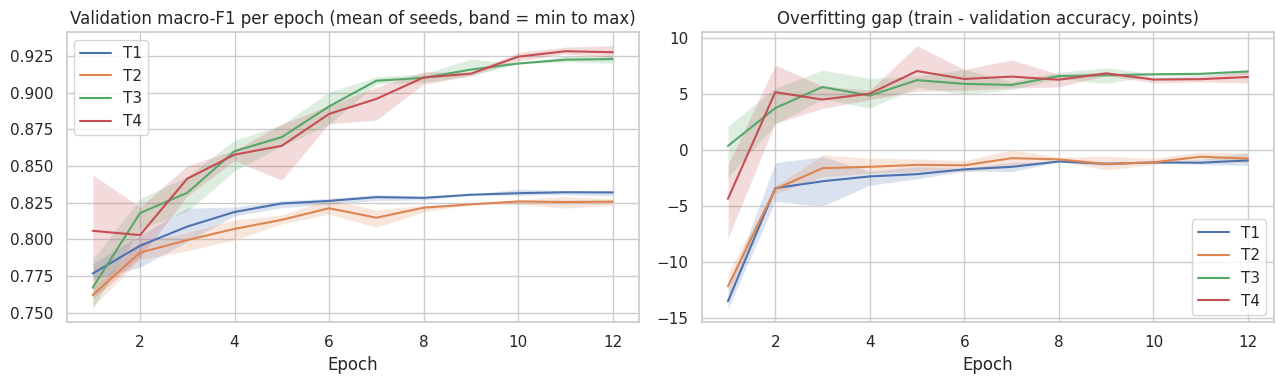

In [6]:
# WHAT: Plot the validation macro-F1 per epoch and the overfitting gap, averaged over seeds.
# WHY:  A gap that widens between training and validation accuracy is the standard sign of
#       overfitting. A frozen backbone should overfit less because far fewer weights learn.
#       If validation is still rising at epoch 12, more epochs could help.
# HOW:  One line per configuration: the mean over seeds, with the lowest and highest seed
#       shown as a shaded band. Gap = training accuracy minus validation accuracy, in points.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for cfg in CONFIGS:
    keys = [f"{cfg}_s{s}" for s in SEEDS]
    f1 = np.array([runs[k]["history"]["val_f1"] for k in keys])
    gap = np.array([np.array(runs[k]["history"]["train_acc"]) -
                    np.array(runs[k]["history"]["val_acc"]) for k in keys]) * 100
    ep = np.arange(1, f1.shape[1] + 1)
    for ax, arr in zip(axes, [f1, gap]):
        ax.plot(ep, arr.mean(0), label=cfg)
        ax.fill_between(ep, arr.min(0), arr.max(0), alpha=0.2)
axes[0].set_title("Validation macro-F1 per epoch (mean of seeds, band = min to max)")
axes[1].set_title("Overfitting gap (train - validation accuracy, points)")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.savefig(OUT / f"{MODEL}_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Frozen runs plateau at about 83% for both training and validation accuracy, so there is no overfitting, but the ImageNet features are not enough for waste photos. Fine-tuned runs reach 99% training against 92–93% validation, a gap of about 7 points. That gap is larger than B0’s (about 5), which fits ResNet-50’s much larger size.

<a id="section-7"></a>
## Section 7: Results Across Seeds

**Goal:** Measure every run once on the held-out test set and report each configuration as mean ± standard deviation over the three seeds. The pooled score is flattered by catalogue-style images, so accuracy is also shown per data source: RealWaste is the closest to what the Pi camera will see.

In [7]:
# WHAT: Load each run's best checkpoint, predict the test set, and build a table with one
#       row per run.
# WHY:  The test photos were never used for training or for choosing the best epoch, so this
#       is the honest comparison. The test numbers are reported here but are NOT used to
#       choose the configuration; Section 8 does that with validation scores only.
#       Plastic recall and the two plastic mistakes (plastic called metal, plastic called
#       glass) are included because they were the weak point of earlier models.
# HOW:  Predictions are collected with gradients off. Per-class recall (the share of each
#       class's test photos that were found) is kept for the heatmap below.
# ------------------------------------------------------------------------------------

def load_net(cfg, seed):
    ck = torch.load(ckpt_path(cfg, seed), map_location=device)
    net = build_model(pretrained=False).to(device)
    net.load_state_dict(ck["model_state"])
    return net.eval(), ck

ip, ig, im = (class_to_idx[c] for c in ["plastic", "glass", "metal"])
rows, recalls = [], {}
for cfg in CONFIGS:
    for seed in SEEDS:
        net, ck = load_net(cfg, seed)
        _, acc, p, y = run_epoch(net, test_loader, eval_criterion)
        del net
        by_src = test_df.assign(pred=p).groupby("src").apply(
            lambda g: (g["pred"] == g["y"]).mean())
        cm = confusion_matrix(y, p, labels=list(range(len(class_names))))
        recalls[(cfg, seed)] = cm.diagonal() / cm.sum(axis=1)
        rows.append({"config": cfg, "seed": seed, "best epoch": ck["epoch"],
                     "val F1": ck["val_f1"], "test acc": acc,
                     "test F1": f1_score(y, p, average="macro"),
                     "RealWaste": by_src["RealWaste"], "GD": by_src["GD"],
                     "Competition": by_src["Competition-only"],
                     "plastic recall": recalls[(cfg, seed)][ip],
                     "plastic->metal": int(cm[ip, im]), "plastic->glass": int(cm[ip, ig]),
                     "train min": runs[f"{cfg}_s{seed}"]["minutes"]})
torch.cuda.empty_cache()

per_run = pd.DataFrame(rows)
display(per_run.round(3))

cols = ["val F1", "test acc", "test F1", "RealWaste", "GD", "Competition", "plastic recall"]
g = per_run.groupby("config")[cols]
summary = g.mean().round(3).astype(str) + " ± " + g.std(ddof=1).round(3).astype(str)
summary["train min"] = per_run.groupby("config")["train min"].mean().round(1)
print("\nMean ± standard deviation over", len(SEEDS), "seeds:")
display(summary)

,config,seed,best epoch,val F1,test acc,test F1,RealWaste,GD,Competition,plastic recall,plastic->metal,plastic->glass,train min
0,T1,42,12,0.833,0.842,0.839,0.776,0.867,0.888,0.722,36,28,21.407
1,T1,7,11,0.830,0.838,0.836,0.763,0.867,0.888,0.709,37,31,11.567
2,T1,123,10,0.834,0.838,0.835,0.762,0.869,0.883,0.738,34,27,11.531
3,T2,42,10,0.827,0.845,0.841,0.779,0.872,0.886,0.770,31,20,11.542
4,T2,7,11,0.829,0.837,0.834,0.766,0.865,0.886,0.715,37,27,11.562
5,T2,123,10,0.827,0.839,0.836,0.778,0.863,0.881,0.725,36,25,11.618
6,T3,42,11,0.921,0.928,0.928,0.904,0.935,0.951,0.883,14,8,23.354
7,T3,7,12,0.925,0.932,0.932,0.901,0.943,0.956,0.883,18,3,23.459
8,T3,123,12,0.923,0.924,0.925,0.897,0.930,0.956,0.867,21,6,23.415
9,T4,42,12,0.932,0.925,0.925,0.897,0.930,0.956,0.871,19,7,23.444



Mean ± standard deviation over 3 seeds:


,val F1,test acc,test F1,RealWaste,GD,Competition,plastic recall,train min
config,,,,,,,,
T1,0.833 ± 0.002,0.839 ± 0.002,0.837 ± 0.002,0.767 ± 0.008,0.868 ± 0.001,0.887 ± 0.003,0.723 ± 0.015,14.8
T2,0.828 ± 0.001,0.841 ± 0.004,0.837 ± 0.004,0.774 ± 0.007,0.867 ± 0.005,0.884 ± 0.003,0.737 ± 0.029,11.6
T3,0.923 ± 0.002,0.928 ± 0.004,0.928 ± 0.003,0.901 ± 0.004,0.936 ± 0.007,0.955 ± 0.003,0.878 ± 0.009,23.4
T4,0.929 ± 0.003,0.927 ± 0.002,0.927 ± 0.002,0.901 ± 0.004,0.932 ± 0.001,0.956 ± 0.002,0.872 ± 0.002,23.5


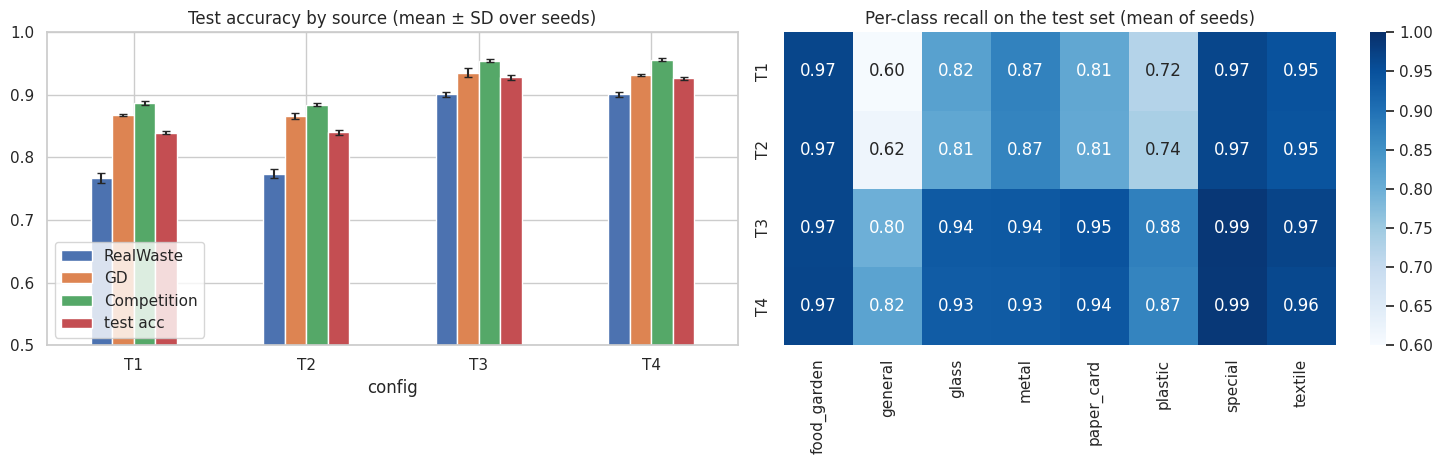

In [8]:
# WHAT: Draw test accuracy by source with seed error bars, and per-class recall as a heatmap.
# WHY:  The bars show whether a configuration's gain is on the real floor photos (RealWaste)
#       or only on the catalogue-style sources, and whether it is bigger than the seed noise.
#       The heatmap shows which classes each configuration finds or misses.
# HOW:  Bar height = mean over seeds; black line = standard deviation. Heatmap = mean recall
#       over seeds, one row per configuration.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
plot_cols = ["RealWaste", "GD", "Competition", "test acc"]
means = per_run.groupby("config")[plot_cols].mean()
sds = per_run.groupby("config")[plot_cols].std(ddof=1)
means.plot.bar(ax=axes[0], rot=0, yerr=sds, capsize=3)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title("Test accuracy by source (mean ± SD over seeds)")
rec = pd.DataFrame({cfg: np.mean([recalls[(cfg, s)] for s in SEEDS], axis=0)
                    for cfg in CONFIGS}, index=class_names).T
sns.heatmap(rec, annot=True, fmt=".2f", cmap="Blues", vmin=0.6, vmax=1, ax=axes[1])
axes[1].set_title("Per-class recall on the test set (mean of seeds)")
plt.tight_layout()
plt.savefig(OUT / f"{MODEL}_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Freezing costs about 9 points of test accuracy and 13 points on RealWaste, and plastic recall falls from 0.87–0.88 to 0.72–0.74. T3 and T4 are a tie on test (92.8% against 92.7%, with identical RealWaste at 90.1%). The same pattern as B0 and MobileNet holds, so the conclusion about the training strategy is consistent across three architectures. Note that in the benchmark notebook ResNet-50 scored 93.5% with a single run. Over three seeds the same recipe averages 92.7%, so that earlier number was about a point too optimistic.

<a id="section-8"></a>
## Section 8: Selection and Save

**Goal:** Choose the final configuration using the **validation** set only, save the final model, and check that the saved file reloads and scores the same.

In [9]:
# WHAT: Pick the configuration with the highest mean validation macro-F1, then the seed with
#       the highest validation macro-F1 inside it, and save that model as the final model.
# WHY:  Choosing with test results would make the test score optimistic, because the test set
#       would have helped pick the winner. Validation photos are for choices; test photos are
#       for reporting. The same rule is applied to every model in the project.
# HOW:  The final checkpoint keeps its "arch", "config" and "seed" keys, so the comparison
#       notebook and the Pi export can rebuild the right network from the file alone.
# ------------------------------------------------------------------------------------

val_by_cfg = per_run.groupby("config")["val F1"].mean()
print("Mean validation macro-F1 per configuration:")
print(val_by_cfg.round(4).to_string())

BEST_CFG = val_by_cfg.idxmax()                 # override by hand only with a written reason
cand = per_run[per_run["config"] == BEST_CFG]
BEST_SEED = int(cand.loc[cand["val F1"].idxmax(), "seed"])
print(f"\nSelected configuration: {BEST_CFG}  ({CONFIGS[BEST_CFG]})")
print(f"Selected seed (best validation F1): {BEST_SEED}")

final_path = OUT / f"verde_final_{MODEL}.pth"
shutil.copy(ckpt_path(BEST_CFG, BEST_SEED), final_path)
json.dump(class_names, open(OUT / "class_names.json", "w"), indent=2)
per_run.round(4).to_csv(OUT / f"{MODEL}_results.csv", index=False)
json.dump({"model": MODEL, "selected_config": BEST_CFG, "selected_seed": BEST_SEED,
           "selection_rule": "highest mean validation macro-F1",
           "seeds": SEEDS, "epochs": EPOCHS}, open(OUT / f"{MODEL}_summary.json", "w"), indent=2)

# --- Reload the saved file on its own and re-measure it ---
ck = torch.load(final_path, map_location=device)
net = build_model(pretrained=False).to(device)
net.load_state_dict(ck["model_state"])
_, acc, p_final, y_final = run_epoch(net.eval(), test_loader, eval_criterion)
row = per_run[(per_run["config"] == BEST_CFG) & (per_run["seed"] == BEST_SEED)].iloc[0]
print(f"\nReloaded {final_path.name}: test accuracy {acc:.1%}  (table: {row['test acc']:.1%})")

print("\nSaved files:")
for f in sorted(OUT.glob("verde_*.pth")):
    print(f"  {f.name:34s} {f.stat().st_size / 1024:8.1f} KB")

Mean validation macro-F1 per configuration:
config
T1    0.8327
T2    0.8276
T3    0.9231
T4    0.9287

Selected configuration: T4  ({'backbone': 'finetune', 'imbalance': 'classweights'})
Selected seed (best validation F1): 42



Reloaded verde_final_resnet50.pth: test accuracy 92.5%  (table: 92.5%)

Saved files:
  verde_final_resnet50.pth            92207.6 KB
  verde_resnet50_T1_s123.pth          92208.0 KB
  verde_resnet50_T1_s42.pth           92207.6 KB
  verde_resnet50_T1_s7.pth            92207.3 KB
  verde_resnet50_T2_s123.pth          92208.0 KB
  verde_resnet50_T2_s42.pth           92207.6 KB
  verde_resnet50_T2_s7.pth            92207.3 KB
  verde_resnet50_T3_s123.pth          92208.0 KB
  verde_resnet50_T3_s42.pth           92207.6 KB
  verde_resnet50_T3_s7.pth            92207.3 KB
  verde_resnet50_T4_s123.pth          92208.0 KB
  verde_resnet50_T4_s42.pth           92207.6 KB
  verde_resnet50_T4_s7.pth            92207.3 KB


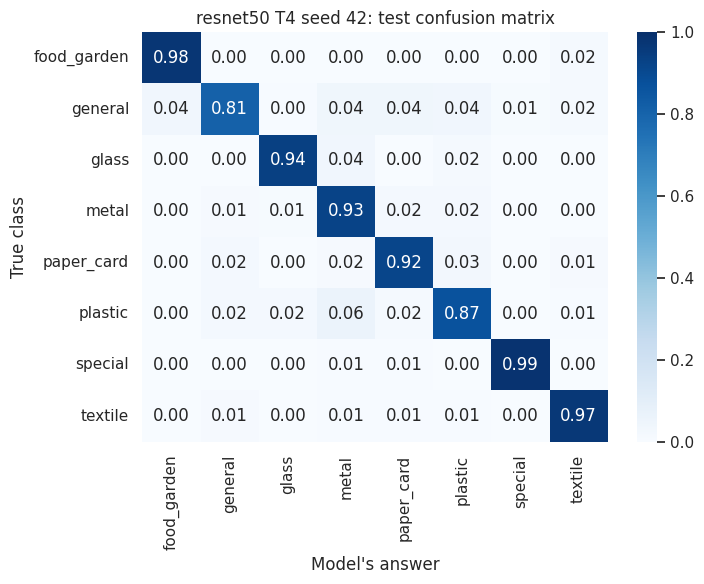

In [10]:
# WHAT: Plot the confusion matrix of the final model on the test set.
# WHY:  The accuracy number hides which classes are mixed up. Rows are the true class,
#       columns the model's answer, so the off-diagonal cells are the mistakes (for example
#       plastic called metal or glass).
# HOW:  Each row is divided by its total, so the numbers are the share of that class's photos.
# ------------------------------------------------------------------------------------

cm = confusion_matrix(y_final, p_final, labels=list(range(len(class_names))))
plt.figure(figsize=(7.5, 6))
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, vmin=0, vmax=1)
plt.xlabel("Model's answer"); plt.ylabel("True class")
plt.title(f"{MODEL} {BEST_CFG} seed {BEST_SEED}: test confusion matrix")
plt.tight_layout()
plt.savefig(OUT / f"{MODEL}_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** T4 was selected on validation (mean 0.929 against 0.923 for T3, a gap of about two standard deviations), seed 42 (the best validation F1 of the three). The reloaded file scores 92.5%, the same as the table. That seed happens to have the lowest test accuracy of the three T4 seeds (92.5% against 92.9% and 92.7%), which is a reminder that validation selection is not perfect, and that the seed-to-seed difference is about 0.4 points.

<a id="section-9"></a>
## Section 9: Try Your Own Photos

**Goal:** Check the models on real photos from your own camera, which tells us more than the dataset score. Click **Choose file**, pick one or more photos from your PC, and the top-3 guesses of the best seed of each configuration are shown side by side. Below the 60% confidence threshold an answer is shown as "not sure", which is what the app would do.

In [11]:
# WHAT: A "Choose file" button. Each photo you pick is resized to 224x224 and added to the
#       page with the top-3 guesses of the best seed of every configuration.
# WHY:  Dataset accuracy does not prove the model works on your camera. Adding photos one
#       by one lets you test many items in a row and compare the configurations on each.
# HOW:  The best seed of each configuration is the one with the highest validation F1. After
#       each pick the button is reset, so the next photo (even the same file) is processed
#       as new. "Clear results" wipes the page and the summary log.
# ------------------------------------------------------------------------------------

import io
import ipywidgets as widgets
from IPython.display import display

THRESHOLD = 0.60
nets = {}
for cfg in CONFIGS:
    part = per_run[per_run["config"] == cfg]
    nets[cfg] = load_net(cfg, int(part.loc[part["val F1"].idxmax(), "seed"]))[0]
log = []                                    # one row per photo, for a summary table

def prepare(img):
    """Any PIL image -> normalised [3, 224, 224] tensor (same steps as the Pi and the app)."""
    img = ImageOps.exif_transpose(img).convert("RGB")
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    img = img.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    return eval_transform(img)

def get_files(value):
    """Works with older (dict) and newer (tuple) ipywidgets."""
    if isinstance(value, dict):
        return [(n, bytes(f["content"])) for n, f in value.items()]
    return [(f["name"], bytes(f["content"])) for f in value]

def show_photo(name, data):
    raw = Image.open(io.BytesIO(data))
    img = ImageOps.exif_transpose(raw).convert("RGB")
    x = prepare(img).unsqueeze(0).to(device)
    row = {"photo": name[:30]}
    fig, axes = plt.subplots(1, 1 + len(nets), figsize=(3.4 * (1 + len(nets)), 3.4))
    axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title(name[:28], fontsize=9)
    for ax, (cfg, net) in zip(axes[1:], nets.items()):
        with torch.no_grad():
            p = torch.softmax(net(x), 1)[0].cpu().numpy()
        top = np.argsort(-p)[:3][::-1]
        ax.barh([class_names[i] for i in top], p[top])
        ax.set_xlim(0, 1)
        answer = class_names[p.argmax()] if p.max() >= THRESHOLD else "not sure"
        ax.set_title(f"{cfg}: {answer} {p.max():.0%}", fontsize=9)
        row[cfg] = f"{answer} {p.max():.0%}"
    log.append(row)
    plt.tight_layout(); plt.show()

uploader = widgets.FileUpload(accept="image/*", multiple=True, description="Choose file")
clear_btn = widgets.Button(description="Clear results")
out = widgets.Output()

def on_upload(change):
    files = get_files(uploader.value)
    if not files:                           # the reset below triggers this once more
        return
    with out:
        for name, data in files:
            show_photo(name, data)
    uploader.value = {} if isinstance(uploader.value, dict) else ()   # ready for the next photo

def on_clear(_):
    out.clear_output()
    log.clear()

uploader.observe(on_upload, names="value")
clear_btn.on_click(on_clear)
display(widgets.HBox([uploader, clear_btn]), out)

Output()

**Finding:** Five real photos were tested with the best seed of each configuration. The food dish was classified correctly with high confidence by all four (T1 77%, T2 74%, T3 93%, T4 87%), and the black glove was classified as textile by all four, although T3 stayed below the 60% threshold (57%). The mouse and the white sheet of paper were “not sure” for every configuration, which is safe but gives the user no answer. The small gadget is the one concern: T3 and T4 called it paper_card at 61% and 63%, just above the threshold, so the app would show a confident answer that is wrong if the item is [fill in the true class]. Frozen models (T1, T2) stayed unsure on it. Compared with the EfficientNet-B0 T3 model, ResNet-50 T3 was weaker on the same photos: B0 got the white paper right (paper_card 73%) and the glove with 84% confidence. This matches the dataset results, where B0 is about 3.6 points better on RealWaste. Five photos are an anecdote, not a score, and the real-photo comparison notebook will measure this properly.

<a id="section-10"></a>
## Section 10: Summary and Limitations

**Summary:** ResNet-50 confirms the training-strategy results from EfficientNet-B0 but is the weakest of the fine-tuned models: 92.7% test accuracy and 90.1% on RealWaste, against 94.4% and 93.7% for B0. It costs 94 MB and about 74 ms per photo. It is not competitive for the Pi or the phone app.

**How to use the result**
1. Commit this notebook (Save & Run All) so the saved files exist as notebook output.
2. Attach this notebook's output to the **real-photo comparison notebook**, which loads every `verde_*.pth` file and scores them all on the same Pi photos.
3. `verde_final_resnet50.pth` stores the model name, configuration and seed, so a later notebook rebuilds the network with `build_model()` and does not have to assume one architecture.
4. Measure the real inference time on the Raspberry Pi before exporting with ExecuTorch.

**Limitations**
- Three seeds give a rough estimate of the noise, not a precise one. Gaps smaller than one standard deviation should not drive a decision.
- Every configuration uses the same learning rate and 12 epochs, to keep the test fair. Frozen runs in particular might do better with a higher learning rate or more epochs.
- Dataset test accuracy is flattered by catalogue-style photos. RealWaste and real Pi photos are the better guide.
- CPU times come from a Kaggle CPU, not a Raspberry Pi. Use them to compare models with each other.
- A network cannot learn items it has never seen, such as watches, mice and other electricals. More Pi training photos of those will help more than a different configuration.
- The ResNets were still improving at epoch 12 in the benchmark, so 12 epochs may slightly understate ResNet-50. If CUDA runs out of memory, set `BATCH_SIZE = 32` in Section 3.
**Next steps:** run the real-photo comparison notebook; capture and label more Pi photos (electricals, batteries, wrappers, textiles) and keep them split between fine-tuning and held-out testing; measure the chosen model on the Pi and export it with ExecuTorch.